# 16 · Real Use Cases in Wind Energy

This is a module of Neural Networks 1002. It assumes [module 02 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) (backpropagation and automatic differentiation), [module 03](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training networks well, baselines, early stopping), [module 05](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) (convolutional networks) and [module 07](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) (time series with neural networks), and it points to modules 08, 09 and 11 of this course.

The first fifteen modules teach one technology at a time on toy data. This last module is different: it is a **narrative capstone with no new experiments**. Five practical notebooks, each testing a neural-network technology on a real problem of the wind-energy sector and comparing it with a classical method, were executed beforehand and are bundled with this course in the folder `wind_cases/`. For each one this module tells **what was tried, which technologies were put to the test, how they were compared with classical methods, what was measured (the negative results included) and what you should take from it**.

Two honest remarks before you start.

1. **The five notebooks are written in Spanish and use the Spanish decimal comma** (`0,58` means 0.58). This module is in English and writes numbers with a decimal point; every number you read here is copied from the notebooks and checked by code (section 2), so you can trust the figures and still open the original to read the full argument, the code and the plots.
2. **Some of the data are licensed for non-commercial use only**, and one offshore lidar file declares no licence at all. Read section 11 before you reuse or publish anything.

The wind-energy examples live here and only here: modules 01 to 15 deliberately used other domains, so that the technologies could be taught without a sector in the way. Here the sector is the point, and the question is the one a practitioner asks: *when did the neural network actually win, and when did a simpler method do better?*

**Contents**

1. The five cases at a glance
2. How every number in this module is checked
3. Case 1: a physics-informed network for the vertical wind profile
4. Case 2: a graph neural network for a wind farm with wakes
5. Case 3: the spectral wave rose, signal processing and no network
6. Case 4: XGBoost against PyTorch on three real problems
7. Case 5: a convolutional network for waves from radar images
8. Synthesis: when did the neural network win, and when not
9. Cross-cutting lessons
10. Extending each case with the newer modules
11. Limits and licences
12. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [02 Backpropagation (1001)](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) | automatic differentiation: a physics-informed loss differentiates the network with respect to its input |
| [03 Training deep networks well (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | strong baselines, early stopping, overfitting on small data, seed noise |
| [05 Convolutional networks (1001)](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) | the small convolutional network of case 5 |
| [07 Time series with neural networks (1001)](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) | temporal splits, persistence as a baseline, multi-horizon forecasting (case 4) |
| [08 Graph neural networks (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/08-graph-neural-networks/) | message passing, the model used for the wind farm (case 2) |
| [09 Scientific machine learning (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/09-scientific-machine-learning/) | physics-informed networks (case 1) and neural operators (extensions) |
| [11 Uncertainty, calibration and robustness (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/11-uncertainty-calibration-and-robustness/) | intervals, distribution shift and out-of-range behaviour (cases 1, 4 and 5) |
| [13 Data-centric AI (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/13-data-centric-ai/) | why labels, not architecture, decided case 5 |

New to pandas, scikit-learn or time-series validation? The [Python 1001 course, time-series section](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/) covers the tools used in the five notebooks.

**Who this is for.** Readers who finished the earlier modules and want to see the technologies meet real, messy, small data, with the unflattering results left in. It is also a template for how to report a model comparison honestly.

**Where these cases differ from industrial practice.** The notebooks use open data sets of a few weeks to two years from a handful of sites, 10 to 30 minute averages and laptop-sized models. Real projects have more sites, longer records, proprietary data and operational constraints. The *mechanisms* (when physics helps, when geometry diversity matters, what labels buy) carry over; the exact numbers do not.

**Run time.** This module only reads five notebook files and draws a few bar charts: well under a minute on a laptop CPU, no GPU, no downloads, no keys.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/16_real_use_cases_wind_energy.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: under a minute, with a peak memory of under 1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. The five cases at a glance

All five notebooks follow the same discipline: a **simple, strong baseline first**, the neural network second, a validation that matches how the model would really be used (later months, a different farm, whole days left out), and a section that says where the network did *not* win.

| # | Problem | Data | Technologies compared | Winner | One-sentence lesson |
|---|---|---|---|---|---|
| 1 | Extrapolate wind speed from low heights up to rotor heights (and down to the surface) | Offshore lidar at ten heights, plus a coastal site and a hill | Power law, logarithmic law, plain MLP, two physics-informed networks (PINN) | Depends on the regime: PINN with few full profiles, noisy data, a surface boundary condition or when estimating friction velocity; plain MLP or log law with clean, abundant data | Physics is a regulariser, not an oracle: it helps when data are scarce or noisy and hurts when the imposed equation does not hold. |
| 2 | Power of every turbine in a farm, with wakes | Two open farms with 10-minute SCADA, plus a synthetic farm simulator with known truth | No-wake curve, Jensen model, MLP, graph neural network (GNN) | GNN on unseen layouts when it trains on many layouts and the true physics is richer than Jensen; Jensen on a new real farm and when the physics is simple | A network trained on one farm learns that farm. Diversity of geometry, not the architecture, buys generalisation. |
| 3 | Directional wave spectrum from a buoy and from satellite radar images | One public buoy week, simulated sea states, eight radar images | Truncated Fourier and maximum-entropy reconstruction, SAR transfer-function inversion (no network) | No network here; buoy and radar complement each other | Four numbers per frequency fix the integral quantities but not the shape of the distribution; this is the physics case 5 relies on. |
| 4 | When is a PyTorch network worth it against gradient-boosted trees? | Real SCADA of one farm and an offshore lidar | XGBoost, MLP, linear regression, persistence | XGBoost on tabular data; MLP slightly better only for long horizons with many related outputs | Start with trees or a linear model; reach for a network when the input is not a table or there are many related outputs. |
| 5 | Wave height, period and direction from radar images | Simulated scenes, then 187 real images validated against a reanalysis | CNN, XGBoost on hand-made features, physical inversion | CNN and XGBoost tie and both beat the physical method on real data; the physical method wins outside the training range in simulation | The value of the network was the labels, not the architecture. |

Open the original notebooks to read the full argument and rerun them (they use the Spanish language and need `pandas`, `xgboost`, `scipy` and `pyarrow` besides the course requirements):

* [01_pinn_perfil_vertical_viento.ipynb](wind_cases/01_pinn_perfil_vertical_viento.ipynb)
* [02_gnn_granja_eolica_estelas.ipynb](wind_cases/02_gnn_granja_eolica_estelas.ipynb)
* [03_rosa_espectral_oleaje.ipynb](wind_cases/03_rosa_espectral_oleaje.ipynb)
* [04_xgboost_vs_pytorch.ipynb](wind_cases/04_xgboost_vs_pytorch.ipynb)
* [05_cnn_oleaje_sar.ipynb](wind_cases/05_cnn_oleaje_sar.ipynb)

## 2. How every number in this module is checked

A narrative module is only worth reading if its numbers are real. So this module never recomputes or invents a figure. Every number quoted in the text below is listed in the dictionary of the next cell together with

* the **notebook** and **section** it comes from,
* a **context phrase** copied verbatim from that notebook (a sentence of its "Lectura" paragraph, a table row or a printed output), and
* the **number string exactly as the notebook writes it** (with the Spanish decimal comma in prose, or a decimal point inside printed tables).

The code then opens the five notebook files and checks, by text search over the markdown and the saved outputs, that the context phrase exists in a cell **and** that the number appears inside that phrase. It prints a table with a pass or fail flag for each number and **stops with an error if any one is missing**, so a typo here, or a change in the original notebook, cannot slip through. The values in the dictionary are also what the bar charts in section 8 are drawn from.

A limit of this check: it proves that a number is in the notebook where we say it is, not that the notebook is right. Statements such as "ERA5 is not the ground truth" are part of the story told below.

In [1]:
import json, os, re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

NB_FILES = {
    "01": "01_pinn_perfil_vertical_viento.ipynb",
    "02": "02_gnn_granja_eolica_estelas.ipynb",
    "03": "03_rosa_espectral_oleaje.ipynb",
    "04": "04_xgboost_vs_pytorch.ipynb",
    "05": "05_cnn_oleaje_sar.ipynb",
}

def find_wind_cases():
    for cand in ["wind_cases", "../wind_cases", "../../wind_cases"]:
        if all(os.path.exists(os.path.join(cand, f)) for f in NB_FILES.values()):
            return cand
    # not found (for example when this notebook is opened alone in Google Colab): fetch the five notebooks from the course repository
    import shutil, subprocess
    subprocess.run(["git", "clone", "--depth", "1", "--sparse", "https://github.com/fborbon/academy.git", "_repo_curso"], check=True)
    subprocess.run(["git", "-C", "_repo_curso", "sparse-checkout", "set", "neural-networks-1002/wind_cases"], check=True)
    shutil.copytree("_repo_curso/neural-networks-1002/wind_cases", "wind_cases", dirs_exist_ok=True)
    shutil.rmtree("_repo_curso", ignore_errors=True)
    if all(os.path.exists(os.path.join("wind_cases", f)) for f in NB_FILES.values()):
        return "wind_cases"
    raise FileNotFoundError("folder wind_cases/ with the five notebooks not found next to this notebook")

WC = find_wind_cases()
print("reading the five notebooks from:", WC)

reading the five notebooks from: wind_cases


In [2]:
# id: (notebook, section, context phrase copied from the notebook, number string as the notebook writes it, what it is)
QUOTED = {
 "pinn_k13a_mlp": ("01", "16", "0,58 frente a 0,72 m/s de la PINN-B", "0,58", "K13A clean data, 3 heights: MLP RMSE (m/s)"),
 "pinn_k13a_pinnb": ("01", "16", "0,58 frente a 0,72 m/s de la PINN-B", "0,72", "K13A clean data: PINN-B RMSE (m/s)"),
 "pinn_epl241_mlp": ("01", "10", "MLP sin física 0.237 0.501 0.804 0.980 1.144", "1.144", "EPL, RMSE at 241 m, MLP (m/s)"),
 "pinn_epl241_log": ("01", "10", "Ley logarítmica 0.296 0.574 0.888 1.079 1.266", "1.266", "EPL, RMSE at 241 m, log law (m/s)"),
 "pinn_epl241_pinnb": ("01", "10", "PINN-B (sólo forma) 0.309 0.575 0.882 1.060 1.225", "1.225", "EPL, RMSE at 241 m, PINN-B (m/s)"),
 "pinn_epl241_pinna": ("01", "10", "PINN-A (completa) 0.368 0.663 0.982 1.155 1.304", "1.304", "EPL, RMSE at 241 m, PINN-A (m/s)"),
 "pinn_epl241_persist": ("01", "10", "Persistencia (V116) 0.412 0.809 1.161 1.334 1.465", "1.465", "EPL, RMSE at 241 m, persistence (m/s)"),
 "pinn_noise_log": ("01", "16", "de 1,08 m/s (ley logarítmica) a 1,03 m/s (un 5 %)", "1,08", "EPL noisy: log law RMSE (m/s)"),
 "pinn_noise_pinnb": ("01", "16", "de 1,08 m/s (ley logarítmica) a 1,03 m/s (un 5 %)", "1,03", "EPL noisy: PINN-B RMSE (m/s)"),
 "pinn_noise_k13a_log": ("01", "16", "de 0,95 m/s (ley logarítmica, la mejor sin PINN) a 0,87 m/s (un 9 %)", "0,95", "K13A noisy: best non-PINN RMSE (m/s)"),
 "pinn_noise_k13a_pinna": ("01", "16", "de 0,95 m/s (ley logarítmica, la mejor sin PINN) a 0,87 m/s (un 9 %)", "0,87", "K13A noisy: PINN-A RMSE (m/s)"),
 "pinn_hill_pinna": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "1,59", "Hill, clean: PINN-A RMSE (m/s)"),
 "pinn_hill_log": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "0,96", "Hill, clean: log law RMSE (m/s)"),
 "pinn_hill_pct": ("01", "16", "1,59 m/s sin ruido frente a 0,96 de la ley logarítmica, un 65 % peor", "65", "Hill: PINN-A worse than log law (%)"),
 "pinn_lambda_01": ("01", "16", "sube a 1,25 y 1,16 m/s, peor que la ley", "1,25", "K13A noisy, PINN-A with lambda 0.1 (m/s)"),
 "pinn_lambda_10": ("01", "16", "sube a 1,25 y 1,16 m/s, peor que la ley", "1,16", "K13A noisy, PINN-A with lambda 10 (m/s)"),
 "pinn_few_mlp191": ("01", "15", "1,20 y 1,64 m/s del MLP global", "1,20", "3 full profiles: global MLP RMSE at 191 m (m/s)"),
 "pinn_few_pinn191": ("01", "15", "la PINN global tiene un RMSE de unos 0,91 m/s a 191 m", "0,91", "3 full profiles: global PINN RMSE at 191 m (m/s)"),
 "pinn_few_gain_epl": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "25", "3 full profiles: PINN gain over MLP at EPL (%)"),
 "pinn_few_gain_hill": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "13", "3 full profiles: gain at the hill (%)"),
 "pinn_bottom_pinna": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "1,10", "Extrapolating down to 63 m: PINN-A RMSE (m/s)"),
 "pinn_bottom_pow": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "1,79", "Extrapolating down to 63 m: power law RMSE (m/s)"),
 "pinn_bottom_mlp": ("01", "17", "a 63 m la PINN-A tiene un RMSE de 1,10 m/s, frente a 1,79 de la ley de potencia (la mejor sin PINN) y 2,41 del MLP: un 39 % menos", "2,41", "Extrapolating down to 63 m: MLP RMSE (m/s)"),
 "pinn_up_pinnb": ("01", "17", "2,00 m/s a 291 m frente a 2,05 del MLP y 2,06 de la ley logarítmica (2 a 3 %)", "2,00", "Extrapolating up to 291 m: PINN-B RMSE (m/s)"),
 "pinn_ustar_pinn": ("01", "18", "8,6 % frente a 15 % del ajuste clásico con datos reales", "8,6", "u* error under strong noise: PINN (%)"),
 "pinn_ustar_fit": ("01", "18", "8,6 % frente a 15 % del ajuste clásico con datos reales", "15", "u* error under strong noise: classical fit (%)"),
 "pinn_ustar_clean_fit": ("01", "18", "error de 4 % frente a 12 % de la PINN-A", "4", "u* error without noise: classical fit (%)"),
 "pinn_ustar_clean_pinn": ("01", "18", "error de 4 % frente a 12 % de la PINN-A", "12", "u* error without noise: PINN-A (%)"),
 "pinn_L_sign": ("01", "18", "con verdad conocida acierta el signo sólo en el 31 % de los perfiles", "31", "PINN-A, sign of 1/L correct, known truth (%)"),
 "pinn_ft_hill_pinn": ("01", "19", "0,96 frente a 1,16 m/s del MLP en la colina, un 17 % menos", "0,96", "Hill, fine-tuned on 3 profiles: PINN RMSE (m/s)"),
 "pinn_ft_hill_mlp": ("01", "19", "0,96 frente a 1,16 m/s del MLP en la colina, un 17 % menos", "1,16", "Hill, fine-tuned on 3 profiles: MLP RMSE (m/s)"),
 "gnn_pen_curve": ("02", "22", "curva sin estelas 113,6 kW, Jensen 104,0 kW", "113,6", "Penmanshiel test, MAE per turbine: no-wake power curve (kW)"),
 "gnn_pen_jensen": ("02", "22", "curva sin estelas 113,6 kW, Jensen 104,0 kW", "104,0", "Penmanshiel test: Jensen (kW)"),
 "gnn_pen_mlp": ("02", "22", "MLP 80,4 kW, GNN con suma 77,1 kW", "80,4", "Penmanshiel test: MLP (kW)"),
 "gnn_pen_gnn": ("02", "22", "MLP 80,4 kW, GNN con suma 77,1 kW", "77,1", "Penmanshiel test: GNN (kW)"),
 "gnn_kel_curve": ("02", "22", "curva sin estelas 116,0 kW, Jensen $k=0{,}075$ 84,2 kW", "116,0", "Kelmarsh (unseen farm): no-wake curve (kW)"),
 "gnn_kel_jensen": ("02", "22", "curva sin estelas 116,0 kW, Jensen $k=0{,}075$ 84,2 kW", "84,2", "Kelmarsh: Jensen k=0.075 (kW)"),
 "gnn_kel_gnn_dir": ("02", "22", "GNN con dirección 120,5 kW (peor que no modelar estelas), GNN solo geometría 110,0 kW", "120,5", "Kelmarsh: GNN with absolute direction (kW)"),
 "gnn_kel_gnn_geom": ("02", "22", "GNN con dirección 120,5 kW (peor que no modelar estelas), GNN solo geometría 110,0 kW", "110,0", "Kelmarsh: GNN geometry only (kW)"),
 "gnn_syn_gnn": ("02", "16", "Por turbina, 43,6 kW frente a 45,8 kW del mejor Jensen", "43,6", "Synthetic, new layouts: GNN MAE per turbine (kW)"),
 "gnn_syn_jensen": ("02", "16", "Por turbina, 43,6 kW frente a 45,8 kW del mejor Jensen", "45,8", "Synthetic, new layouts: best Jensen (kW)"),
 "gnn_syn_park_gnn": ("02", "16", "0,79 % frente a 0,97 % de la potencia instalada (un 19 % menos)", "0,79", "Synthetic: GNN farm-total error (% installed)"),
 "gnn_syn_park_jen": ("02", "16", "0,79 % frente a 0,97 % de la potencia instalada (un 19 % menos)", "0,97", "Synthetic: Jensen farm-total error (% installed)"),
 "gnn_A_gnn": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "33,9", "Fixed layout A: GNN that never saw A (kW)"),
 "gnn_A_jensen": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "41,2", "Fixed layout A: fitted Jensen (kW)"),
 "gnn_A_mlp": ("02", "16", "La GNN que **no ha visto A** (33,9 kW) gana al Jensen ajustado (41,2 kW) y al MLP entrenado **en A** (46,4 kW)", "46,4", "Fixed layout A: MLP trained on A (kW)"),
 "gnn_L1_own": ("02", "17", "30,7 kW en su propio parque (el mejor número de toda la tabla) y 59,4 kW en parques nuevos, un 30 % **peor** que Jensen", "30,7", "One training layout: error on its own farm (kW)"),
 "gnn_L1_new": ("02", "17", "30,7 kW en su propio parque (el mejor número de toda la tabla) y 59,4 kW en parques nuevos, un 30 % **peor** que Jensen", "59,4", "One training layout: error on new farms (kW)"),
 "gnn_simple_jensen": ("02", "18", "Jensen con $k$ ajustado (27,2 kW por turbina, 0,33 % en el parque)", "27,2", "Simple physics: fitted Jensen (kW)"),
 "gnn_simple_truth": ("02", "18", "(25,3 kW, 0,31 %)", "25,3", "Simple physics: noiseless truth (kW)"),
 "gnn_simple_gnn100": ("02", "18", "La GNN con 100 layouts se queda en 42,9 kW (0,80 %), y con un layout en 55,4 kW", "42,9", "Simple physics: GNN, 100 layouts (kW)"),
 "gnn_simple_gnn1": ("02", "18", "La GNN con 100 layouts se queda en 42,9 kW (0,80 %), y con un layout en 55,4 kW", "55,4", "Simple physics: GNN, 1 layout (kW)"),
 "gnn_abl_base": ("02", "19", "Sin desplazamiento transversal (\"solo distancia\") el error sube de 44,3 a 62,9 kW", "44,3", "Ablation: base GNN (kW)"),
 "gnn_abl_dist": ("02", "19", "Sin desplazamiento transversal (\"solo distancia\") el error sube de 44,3 a 62,9 kW", "62,9", "Ablation: distance-only edges (kW)"),
 "gnn_abl_nowind": ("02", "19", "sin referencia del viento (offsets este/norte y la dirección en el nodo) sube a 68,2 kW, peor que Jensen", "68,2", "Ablation: no wind reference frame (kW)"),
 "gnn_abl_1layer": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "69,2", "Chained wakes: 1 layer (kW)"),
 "gnn_abl_jensen": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "64,4", "Chained wakes: Jensen (kW)"),
 "gnn_abl_3layer": ("02", "19", "69,2 kW con 1 capa (peor que Jensen, 64,4 kW), 58,5 kW con 2 y 54,5 kW con 3", "54,5", "Chained wakes: 3 layers (kW)"),
 "gnn_ft_jensen2w": ("02", "20", "Con 2 semanas de datos locales gana Jensen ajustado** (83,0 kW frente a 85,7 kW del ajuste fino)", "83,0", "Kelmarsh, 2 weeks local data: fitted Jensen (kW)"),
 "gnn_ft_gnn2w": ("02", "20", "Con 2 semanas de datos locales gana Jensen ajustado** (83,0 kW frente a 85,7 kW del ajuste fino)", "85,7", "Kelmarsh, 2 weeks: pre-trained GNN fine-tuned (kW)"),
 "gnn_ft_jensen3m": ("02", "20", "con 3 meses gana el ajuste fino** (77,3 frente a 82,3 kW por turbina, un 6 % menos", "82,3", "Kelmarsh, 3 months: fitted Jensen (kW)"),
 "gnn_ft_gnn3m": ("02", "20", "con 3 meses gana el ajuste fino** (77,3 frente a 82,3 kW por turbina, un 6 % menos", "77,3", "Kelmarsh, 3 months: fine-tuned GNN (kW)"),
 "gnn_ft_scratch": ("02", "20", "es peor en las tres ventanas (101, 92 y 84 kW)", "101", "Kelmarsh: GNN trained from scratch, 2-week window (kW)"),
 "wave_hm0_err": ("03", "8", "boya + MEM 2.16 12.80 8.83 2.92 20.13 1.48", "1.48", "Synthetic sea, buoy + MEM: Hm0 error (%)"),
 "wave_L1_mem": ("03", "8", "Error relativo L1 de E(f,θ): MEM 57 % Fourier 56 %", "57", "Single record, L1 error of E(f,theta): MEM (%)"),
 "wave_L1_four": ("03", "8", "Error relativo L1 de E(f,θ): MEM 57 % Fourier 56 %", "56", "Single record: truncated Fourier (%)"),
 "wave_L1_mem5": ("03", "8", "mean -2.21 12.8 -0.52 0.42 0.48 50.99", "50.99", "5 seeds, mean L1 error: MEM (%)"),
 "wave_L1_four5": ("03", "8", "L1_Fourier mean 54.09", "54.09", "5 seeds, mean L1 error: Fourier (%)"),
 "wave_neg_cells": ("03", "6", "Fourier truncado: 32 % de las celdas (f,θ) son negativas", "32", "Truncated Fourier: negative cells (%)"),
 "wave_real_hm0": ("03", "10", "Hm0 = 3.69 m (NDBC WVHT = 3.8 m)", "3.69", "Real buoy, one sea state: Hm0 (m)"),
 "wave_real_ndbc": ("03", "10", "Hm0 = 3.69 m (NDBC WVHT = 3.8 m)", "3.8", "Same, published by the buoy operator (m)"),
 "wave_mis_wind": ("03", "11", "Mediana de |desalineación|: mar de viento 37°, swell 67°", "37", "Median misalignment with wind: wind sea (deg)"),
 "wave_mis_swell": ("03", "11", "Mediana de |desalineación|: mar de viento 37°, swell 67°", "67", "Median misalignment with wind: swell (deg)"),
 "wave_sar_dir": ("03", "12", "La **dirección** se recupera con 1° a 4° de error", "4", "Synthetic SAR scene, direction error upper bound (deg)"),
 "wave_sar_hm0": ("03", "12", "y $H_{m0}$ sale entre un 1 % y un 6 % por debajo de la parte visible", "6", "Synthetic SAR scene, Hm0 below visible part, upper bound (%)"),
 "wave_mod_lin": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "1,2", "Linear-model modulation, upper (-)"),
 "wave_mod_real": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,30", "Real SAR scenes, rms modulation, upper (-)"),
 "wave_sar_hs_max": ("03", "12", "$H_{m0}$ de 1,0 a 7,0 m", "7,0", "Eight real SAR scenes: largest Hm0 (m)"),
 "wave_misaligned": ("03", "13", "Fracción del tiempo con swell desalineado más de 45° respecto al viento: 58 %", "58", "One week of buoy data: swell misaligned more than 45 deg (%)"),
 "xgb_n500_xgb": ("04", "3", "0 500 41.64 62.53 57.63 68.59", "41.64", "500 rows: XGBoost MAE (kW)"),
 "xgb_n500_mlp": ("04", "3", "0 500 41.64 62.53 57.63 68.59", "62.53", "500 rows: MLP MAE (kW)"),
 "xgb_n2000_xgb": ("04", "3", "1 2000 37.62 43.23 42.09 44.31", "37.62", "2000 rows: XGBoost (kW)"),
 "xgb_n2000_mlp": ("04", "3", "1 2000 37.62 43.23 42.09 44.31", "43.23", "2000 rows: MLP (kW)"),
 "xgb_nall_xgb": ("04", "3", "4 268086 30.90 31.31 31.08 31.72", "30.90", "All 268k rows: XGBoost (kW)"),
 "xgb_nall_mlp": ("04", "3", "4 268086 30.90 31.31 31.08 31.72", "31.31", "All 268k rows: MLP (kW)"),
 "xgb_oor_xgb": ("04", "4", "XGBoost, objetivo directo 0.628 5.434", "5.434", "Out of range: XGBoost direct target RMSE (m/s)"),
 "xgb_oor_ridge": ("04", "4", "regresión lineal (Ridge) 0.566 0.839", "0.839", "Out of range: linear (Ridge) RMSE (m/s)"),
 "xgb_oor_ratio": ("04", "4", "XGBoost, objetivo = cociente con ws_141 0.652 0.923", "0.923", "Out of range: XGBoost with ratio target (m/s)"),
 "xgb_oor_mlp": ("04", "4", "MLP 0.622 1.430", "1.430", "Out of range: MLP (m/s)"),
 "xgb_oor_persist": ("04", "4", "persistencia (ws_141 en todas las alturas) 0.811 1.100", "1.100", "Out of range: persistence (m/s)"),
 "xgb_time_ridge": ("04", "4", "regresión lineal (Ridge) 0.566 0.839", "0.566", "Temporal split: linear (Ridge) RMSE (m/s)"),
 "xgb_time_mlp": ("04", "4", "MLP 0.622 1.430", "0.622", "Temporal split: MLP RMSE (m/s)"),
 "xgb_fc_xgb": ("04", "5", "XGBoost: 12 modelos, 156 s en total | MAE medio 13.23 % de P_nom (persistencia 13.96 %)", "13.23", "Multi-horizon: XGBoost mean MAE (% of rated)"),
 "xgb_fc_persist": ("04", "5", "XGBoost: 12 modelos, 156 s en total | MAE medio 13.23 % de P_nom (persistencia 13.96 %)", "13.96", "Multi-horizon: persistence (%)"),
 "xgb_fc_mlp0": ("04", "5", "MLP semilla 0: mejor época 11, 16 s, MAE medio 13.25 %", "13.25", "Multi-horizon: MLP seed 0 (%)"),
 "xgb_fc_mlp2": ("04", "5", "MLP semilla 2: mejor época 6, 18 s, MAE medio 13.11 %", "13.11", "Multi-horizon: MLP seed 2 (%)"),
 "xgb_fc_30min_xgb": ("04", "5", "A 30 min gana XGBoost (6,91 % frente a 7,61 %", "6,91", "30 min horizon: XGBoost (%)"),
 "xgb_fc_30min_mlp": ("04", "5", "A 30 min gana XGBoost (6,91 % frente a 7,61 %", "7,61", "30 min horizon: MLP (%)"),
 "xgb_fc_6h_xgb": ("04", "5", "17,64 % frente a 17,30 % a 6 h", "17,64", "6 h horizon: XGBoost (%)"),
 "xgb_fc_6h_mlp": ("04", "5", "17,64 % frente a 17,30 % a 6 h", "17,30", "6 h horizon: MLP (%)"),
 "xgb_fc_cost_xgb": ("04", "5", "XGBoost necesita un modelo por horizonte: 156 s para los 12", "156", "Training cost, 12 horizons: XGBoost (s)"),
 "xgb_fc_cost_mlp": ("04", "5", "El MLP entrena **uno solo** en unos 17 s por semilla", "17", "Training cost: one MLP per seed (s)"),
 "cnn_A_phys": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "3,1", "Test A (linear, in range): physical inversion Hm0 mean error (%)"),
 "cnn_A_cnn": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "6,3", "Test A: CNN (%)"),
 "cnn_A_xgb": ("05", "4", "El error medio de $H_{m0}$ es de 3,1 % con la inversión física (es la inversa exacta del simulador) frente a 6,3 % de la CNN (± 0,2 entre semillas) y 7,5 % de XGBoost", "7,5", "Test A: XGBoost (%)"),
 "cnn_B_phys": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "41", "Test B (saturated): physical inversion Hm0 bias (%, negative)"),
 "cnn_B_cnnlin": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "51", "Test B: CNN trained on linear scenes, bias (%, negative)"),
 "cnn_B_cnnmix": ("05", "4", "CNN, entrenada con mezcla -3.63", "3.63", "Test B: CNN trained on a mix, bias (%, negative)"),
 "cnn_B_xgbmix": ("05", "4", "XGBoost, entrenado con mezcla -2.41", "2.41", "Test B: XGBoost trained on a mix, bias (%, negative)"),
 "cnn_B_rmse_cnn": ("05", "4", "CNN, entrenada con mezcla -3.63 0.49", "0.49", "Test B: CNN mix Hm0 RMSE (m)"),
 "cnn_B_rmse_xgb": ("05", "4", "XGBoost, entrenado con mezcla -2.41 0.63", "0.63", "Test B: XGBoost mix Hm0 RMSE (m)"),
 "cnn_C_phys": ("05", "4", "Se mantiene con un error de 4,8 %, mientras que XGBoost (−24 %) y la CNN (−16 a −18 %)", "4,8", "Test C (waves higher than seen): physical inversion error (%)"),
 "cnn_C_xgb": ("05", "4", "Se mantiene con un error de 4,8 %, mientras que XGBoost (−24 %) y la CNN (−16 a −18 %)", "24", "Test C: XGBoost bias (%, negative)"),
 "cnn_mod_lin": ("05", "2", "modulación rms mediana: lineal 0.98 | saturado 0.32 | 8 viñetas reales 0.25", "0.98", "Median rms modulation, linear simulation (-)"),
 "cnn_mod_real": ("05", "2", "modulación rms mediana: lineal 0.98 | saturado 0.32 | 8 viñetas reales 0.25", "0.25", "Median rms modulation, real scenes (-)"),
 "cnn_pilot_cnn": ("05", "6.4", "su RMSE (0,67 m) iguala al de la referencia de la media (0,64 m)", "0,67", "8-image pilot: CNN RMSE (m)"),
 "cnn_pilot_mean": ("05", "6.4", "su RMSE (0,67 m) iguala al de la referencia de la media (0,64 m)", "0,64", "8-image pilot: always-the-mean RMSE (m)"),
 "cnn_phys_bias": ("05", "6.6", "Sesgo de **-0,45 m (-13 %)** respecto al swell", "-0,45", "187 images: physical method Hs bias vs ERA5 swell (m)"),
 "cnn_phys_rmse": ("05", "6.6", "y el RMSE de 1,10 m, **peor que predecir siempre la media (0,98 m)**", "1,10", "187 images: physical method RMSE (m)"),
 "cnn_phys_dir": ("05", "6.6", "Error medio de **22,5°** (mediano 20,9°)", "22,5", "187 images: physical method mean direction error (deg)"),
 "cnn_phys_Tcorr": ("05", "6.6", "correlación de **0,04**", "0,04", "187 images: physical method period correlation (-)"),
 "cnn_hs_mean": ("05", "6.7", "media 0.00 0.99 -0.17", "0.99", "Day-grouped CV, Hs RMSE: always the mean (m)"),
 "cnn_hs_meta": ("05", "6.7", "solo metadatos 0.01 1.10 0.04", "1.10", "Hs RMSE: metadata only (control) (m)"),
 "cnn_hs_cal": ("05", "6.7", "físico calibrado -0.00 0.84 0.51", "0.84", "Hs RMSE: calibrated physical method (m)"),
 "cnn_hs_xgb": ("05", "6.7", "XGBoost (rasgos CWAVE) 0.00 0.67 0.73", "0.67", "Hs RMSE: XGBoost (m)"),
 "cnn_hs_cnn": ("05", "6.7", "CNN -0.01 0.61 0.79", "0.61", "Hs RMSE: CNN (m)"),
 "cnn_T_mean": ("05", "6.7", "media -0.00 1.17 -0.25", "1.17", "Period RMSE: always the mean (s)"),
 "cnn_T_cal": ("05", "6.7", "físico calibrado 0.00 1.19 -0.27", "1.19", "Period RMSE: calibrated physical method (s)"),
 "cnn_T_xgb": ("05", "6.7", "XGBoost (rasgos CWAVE) -0.02 0.55 0.88", "0.55", "Period RMSE: XGBoost (s)"),
 "cnn_T_cnn": ("05", "6.7", "CNN -0.03 0.66 0.82", "0.66", "Period RMSE: CNN (s)"),
 "cnn_month_corr": ("05", "6.9", "correlación de la media mensual de Hs, CNN frente a ERA5: 0.91", "0.91", "Monthly mean Hs, CNN vs ERA5, correlation (10 months)"),
 "cnn_july": ("05", "6.9", "4,14 m frente a 4,70 m en julio", "4,14", "July mean Hs by CNN (m)"),
 "cnn_july_era5": ("05", "6.9", "4,14 m frente a 4,70 m en julio", "4,70", "July mean Hs by ERA5 (m)"),
 "cnn_probe_hs": ("05", "6.8", "recupera la altura con $R^2$ = 0,66 y el periodo con 0,69", "0,66", "Linear probe on CNN features: R2 for height (-)"),
 "cnn_probe_wv": ("05", "6.8", "se recupera con $R^2$ = 0,96", "0,96", "Linear probe: R2 for the sub-swath label (-)"),
 "cnn_phys_pct": ("05", "6.6", "Sesgo de **-0,45 m (-13 %)** respecto al swell", "-13", "187 images: physical method Hs bias vs ERA5 swell (%)"),
 "cnn_gain_hs_xgb": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "32", "Gain over the mean in height: XGBoost (%)"),
 "cnn_gain_hs_cnn": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "38", "Gain over the mean in height: CNN (%)"),
 "cnn_gain_T_xgb": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "53", "Gain over the mean in period: XGBoost (%)"),
 "cnn_gain_T_cnn": ("05", "6.7", "XGBoost y la CNN mejoran a la media un 32 % y un 38 % en altura, y un 53 % y un 44 % en periodo", "44", "Gain over the mean in period: CNN (%)"),
 "cnn_images": ("05", "6.5", "187 imágenes, 86 días distintos, 1094 recortes", "187", "Real images in the one-site study (count)"),
 "cnn_days": ("05", "6.5", "187 imágenes, 86 días distintos, 1094 recortes", "86", "Distinct days, i.e. independent samples at most (count)"),
 "cnn_params": ("05", "3", "unos 28 000 parámetros", "28 000", "CNN size (parameters)"),
 "gnn_params": ("02", "9", "parámetros GNN: 13921 | parámetros MLP: 7182", "13921", "GNN size (parameters)"),
 "gnn_pen_turb": ("02", "2", "**Penmanshiel** (Escocia): 14 turbinas de 2,05 MW", "14", "Penmanshiel turbines (count)"),
 "gnn_kel_turb": ("02", "2", "**Kelmarsh** (Inglaterra): 6 turbinas de 2,05 MW", "6", "Kelmarsh turbines (count)"),
 "pinn_heights": ("01", "5", "Este lidar tiene **10 alturas** (63, 91, 116, 141, 166, 191, 216, 241, 266 y 291 m)", "10", "EPL lidar heights (count)"),
 "pinn_profiles": ("01", "5", "Quedan 20,856 perfiles de 10 min (87%)", "20,856", "EPL profiles after quality control (count)"),
 "pinn_testprof": ("01", "7", "Cada método resuelve **400 problemas independientes**", "400", "Test profiles per method (count)"),
 "wave_spectra": ("03", "10", "337 espectros entre 2026-11-16 19:20:00", "337", "Real buoy spectra in the week (count)"),
 "wave_sar_scenes": ("03", "12", "y de ellas con **8** de espectro muy marcado", "8", "Real SAR scenes used in the spectral notebook (count)"),
 "xgb_rows": ("04", "2", "filas: entrenamiento 268,086", "268,086", "Training rows of the SCADA study (count)"),
 "xgb_outputs": ("04", "5", "Son 168 salidas por muestra", "168", "Outputs per sample in the multi-horizon task (count)"),
 "xgb_cost_ratio": ("04", "5", "(unas 9 veces menos)", "9", "One MLP trains about this many times faster than 12 XGBoost models (x)"),
 "pinn_epl241_pow": ("01", "10", "Ley de potencia 0.306 0.591 0.922 1.150 1.379", "1.379", "EPL, RMSE at 241 m, power law (m/s)"),
 "pinn_leg_log": ("01", "16", "en LEG la PINN-B lo baja de 0,81 a 0,70 m/s (un 14 %)", "0,81", "Coastal site LEG, noisy: log law RMSE (m/s)"),
 "pinn_leg_pinn": ("01", "16", "en LEG la PINN-B lo baja de 0,81 a 0,70 m/s (un 14 %)", "0,70", "Coastal site LEG, noisy: PINN-B RMSE (m/s)"),
 "pinn_hillnoise_pinn": ("01", "16", "En Altahullion la PINN-B queda a la par de la ley logarítmica (1,05 frente a 1,08 m/s)", "1,05", "Hill, noisy: PINN-B RMSE (m/s)"),
 "pinn_hillnoise_log": ("01", "16", "En Altahullion la PINN-B queda a la par de la ley logarítmica (1,05 frente a 1,08 m/s)", "1,08", "Hill, noisy: log law RMSE (m/s)"),
 "wave_mod_lin_lo": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,8", "Linear-model modulation, lower (-)"),
 "wave_mod_real_lo": ("03", "12", "modulaciones de 0,8 a 1,2, mientras que las viñetas reales tienen entre 0,16 y 0,30", "0,16", "Real SAR scenes, rms modulation, lower (-)"),
 "wave_sar_dir_lo": ("03", "12", "La **dirección** se recupera con 1° a 4° de error", "1", "Synthetic SAR scene, direction error lower bound (deg)"),
 "wave_sar_hm0_lo": ("03", "12", "y $H_{m0}$ sale entre un 1 % y un 6 % por debajo de la parte visible", "1", "Synthetic SAR scene, Hm0 below visible part, lower bound (%)"),
 "wave_sar_hs_min": ("03", "12", "$H_{m0}$ de 1,0 a 7,0 m", "1,0", "Eight real SAR scenes: smallest Hm0 (m)"),
 "cnn_C_cnn_lo": ("05", "4", "XGBoost (−24 %) y la CNN (−16 a −18 %)", "16", "Test C: CNN bias, smaller magnitude (%, negative)"),
 "cnn_C_cnn_hi": ("05", "4", "XGBoost (−24 %) y la CNN (−16 a −18 %)", "18", "Test C: CNN bias, larger magnitude (%, negative)"),
 "cnn_B_xgblin": ("05", "4", "La inversión física subestima $H_{m0}$ un 41 %, XGBoost y la CNN lineales un 49 y un 51 %", "49", "Test B: XGBoost trained on linear scenes, bias (%, negative)"),
 "cnn_T_meta": ("05", "6.7", "solo metadatos 0.01 1.29 -0.01", "1.29", "Period RMSE: metadata only (control) (s)"),
 "cnn_T_raw": ("05", "6.7", "físico crudo 3.02 4.55 0.04", "4.55", "Period RMSE: raw physical method (s)"),
 "gnn_mlp_params": ("02", "9", "parámetros GNN: 13921 | parámetros MLP: 7182", "7182", "MLP size (parameters)"),
 "pinn_few_gain_k13a": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "6", "3 full profiles: gain at the second platform (%)"),
 "pinn_few_gain_leg": ("01", "16", "un 25 % en EPL, un 13 % en la colina, un 6 % en K13A y un 5 % en LEG", "5", "3 full profiles: gain at the coastal site (%)"),
 "pinn_energy_lo": ("01", "1", "se traduce aproximadamente en un 1,5 a 2,5 % de error en la producción anual", "1,5", "1 % speed bias gives this annual-energy error, lower (%)"),
 "pinn_energy_hi": ("01", "1", "se traduce aproximadamente en un 1,5 a 2,5 % de error en la producción anual", "2,5", "1 % speed bias gives this annual-energy error, upper (%)"),
 "pinn_bias1": ("01", "1", "un error sistemático (sesgo) del 1 % en la velocidad media", "1", "Speed bias used in the example (%)"),
 "pinn_flat": ("01", "10", "se aplana por encima de 150 m", "150", "Real profile flattens above this height (m)"),
 "pinn_surface_layer": ("01", "3", "aproximadamente el 10 % inferior de la capa límite", "10", "Surface layer is about this share of the boundary layer (%)"),
 "pinn_shape_range": ("01", "4", "de 40 a 320 m | no | sólo se impone la *forma* del perfil", "40", "PINN-B imposes the shape from this height (m)"),
 "pinn_out_of_layer": ("01", "10", "pero a 60 a 240 m estamos con frecuencia fuera de la capa superficial", "60", "Heights of interest often outside the surface layer, from (m)"),
 "pinn_train_heights": ("01", "7", "sólo las alturas 63, 91 y 116 m", "63", "Lowest training height (m)"),
 "pinn_test_heights": ("01", "7", "141, 166, 191, 216 y 241 m, que **nunca** se usan para ajustar ningún método", "141", "Lowest test height (m)"),
 "wave_station": ("03", "10", "Datos reales: boya NDBC 46042", "46042", "Buoy station used (id)"),
 "wave_sar_min": ("03", "14", "solo longitudes de onda de más de unos 100 a 120 m", "100", "Radar sees only waves longer than this (m)"),
 "xgb_fc_mlp1": ("04", "5", "MLP semilla 1: mejor época 8, 18 s, MAE medio 13.20 %", "13.20", "Multi-horizon: MLP seed 1 (%)"),
 "xgb_time_persist": ("04", "4", "persistencia (ws_141 en todas las alturas) 0.811 1.100", "0.811", "Temporal split: persistence RMSE (m/s)"),
 "xgb_time_xgbdir": ("04", "4", "XGBoost, objetivo directo 0.628 5.434", "0.628", "Temporal split: XGBoost direct RMSE (m/s)"),
 "xgb_time_xgbratio": ("04", "4", "XGBoost, objetivo = cociente con ws_141 0.652 0.923", "0.652", "Temporal split: XGBoost ratio RMSE (m/s)"),
 "xgb_gap": ("04", "3", "La diferencia ya es de un 1 %, del tamaño del ruido de una semilla", "1", "All-rows gap between the two models (%)"),
}

def norm(s):
    return re.sub(r"\s+", " ", s).strip()

def cell_texts(path):
    # one searchable string per cell: markdown or code source, plus saved text outputs
    nb = json.load(open(path, encoding="utf-8"))
    out = []
    for c in nb["cells"]:
        t = "".join(c["source"])
        for o in c.get("outputs", []):
            if o.get("output_type") == "stream":
                t += "\n" + "".join(o.get("text", []))
            elif "data" in o and "text/plain" in o["data"]:
                t += "\n" + "".join(o["data"]["text/plain"])
        out.append(norm(t))
    return out

TEXTS = {k: cell_texts(os.path.join(WC, f)) for k, f in NB_FILES.items()}

rows, failed = [], []
for key, (nb, sec, ctx, num, what) in QUOTED.items():
    in_phrase = num in ctx
    in_notebook = any(norm(ctx) in t for t in TEXTS[nb])
    ok = in_phrase and in_notebook
    rows.append((key, nb, sec, num, ok, what))
    if not ok:
        failed.append(key)

print(f"{'id':24s} nb  section  number      check  what")
for key, nb, sec, num, ok, what in rows:
    print(f"{key:24s} {nb}  {sec:7s}  {num:10s}  {'PASS' if ok else 'FAIL'}   {what}")
print()
print(f"{len(rows) - len(failed)} of {len(rows)} quoted numbers verified in the notebooks")
if failed:
    raise AssertionError("quoted numbers NOT found in the notebooks: " + ", ".join(failed))

def V(key):
    # numeric value of a verified quoted number (decimal comma or point; thousands separators ignored)
    s = QUOTED[key][3].replace(" ", "")
    if re.fullmatch(r"-?\d{1,3}(,\d{3})+", s):
        s = s.replace(",", "")
    return float(s.replace(",", "."))

id                       nb  section  number      check  what
pinn_k13a_mlp            01  16       0,58        PASS   K13A clean data, 3 heights: MLP RMSE (m/s)
pinn_k13a_pinnb          01  16       0,72        PASS   K13A clean data: PINN-B RMSE (m/s)
pinn_epl241_mlp          01  10       1.144       PASS   EPL, RMSE at 241 m, MLP (m/s)
pinn_epl241_log          01  10       1.266       PASS   EPL, RMSE at 241 m, log law (m/s)
pinn_epl241_pinnb        01  10       1.225       PASS   EPL, RMSE at 241 m, PINN-B (m/s)
pinn_epl241_pinna        01  10       1.304       PASS   EPL, RMSE at 241 m, PINN-A (m/s)
pinn_epl241_persist      01  10       1.465       PASS   EPL, RMSE at 241 m, persistence (m/s)
pinn_noise_log           01  16       1,08        PASS   EPL noisy: log law RMSE (m/s)
pinn_noise_pinnb         01  16       1,03        PASS   EPL noisy: PINN-B RMSE (m/s)
pinn_noise_k13a_log      01  16       0,95        PASS   K13A noisy: best non-PINN RMSE (m/s)
pinn_noise_k13a_pinna    0

## 3. Case 1: a physics-informed network for the vertical wind profile

**Notebook:** [01_pinn_perfil_vertical_viento.ipynb](wind_cases/01_pinn_perfil_vertical_viento.ipynb). **Connects to:** [module 09 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/09-scientific-machine-learning/) (physics-informed networks) and [module 02 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) (automatic differentiation).

**The problem.** A wind measurement campaign often covers the low heights well, but a modern turbine has its hub, and the tip of its blade, far above. The speed there has to be *estimated*, and a systematic error of 1 % in speed becomes roughly 1.5 to 2.5 % in annual energy (notebook 01, section 1). The task: given the speed at three low heights (63, 91 and 116 m), predict it at five higher ones (141 to 241 m) that no method is allowed to fit on.

**Data and licence.** A wind lidar (light detection and ranging, a laser instrument that measures wind speed) on a fixed offshore platform in the North Sea, reporting 10-minute statistics at 10 heights from 63 to 291 m, year 2017: 20,856 profiles after quality control, and a test sample of 400 profiles (notebook 01, sections 5 and 7). The data are a free download from a Dutch national offshore wind-measurement portal; **the file declares no explicit licence**, so the notebook uses it for teaching with attribution and says to check the portal terms before commercial use. Later sections add three more sites: a second offshore platform (K13A), a coastal lighthouse (LEG) and a hill on land.

**Methods compared.** (i) the empirical **power law**; (ii) the **logarithmic law**; (iii) a small **MLP** with no physics, one network per 10-minute profile (400 networks trained in parallel); (iv) **PINN-A**, a network whose loss adds the residual of the Monin-Obukhov (MO) equation, which describes how wind shear depends on atmospheric stability, imposed from the sea surface where the speed must be zero; (v) **PINN-B**, which imposes only the *shape* of the MO profile between 40 and 320 m, with no surface condition; and **persistence** (repeat the last measured speed). A weight called $\lambda$ (lambda) sets how much the loss trusts the equation relative to the data. Later experiments use one global network trained on many profiles, with and without the physics residual.

**Result 1: with clean data and three heights the PINN did not win.** RMSE (root mean squared error, the typical size of the error) at 241 m on the first offshore platform, in m/s (notebook 01, section 10):

| Method | RMSE at 241 m [m/s] |
|---|---|
| Persistence | 1.465 |
| Power law | 1.379 |
| Logarithmic law | 1.266 |
| PINN-A (physics from the sea surface) | 1.304 |
| PINN-B (shape only) | 1.225 |
| MLP, no physics | 1.144 |

*Reading.* Every method beats persistence and the error grows with distance from the last measurement. The plain MLP is best, and the notebook explains why this is partly luck: a `tanh` network flattens outside the data, which happens to match the real profile that flattens above about 150 m. On the second offshore platform the MLP is clearly best (RMSE 0.58 m/s against 0.72 m/s for PINN-B, section 16). PINN-A is worse than the log law because the MO theory describes the lowest tenth of the boundary layer, and at 60 to 240 m the profile is often outside it.

**Result 2: with noise, with few full profiles, or with a boundary condition, the physics helped.**

| Situation | What was measured | Source |
|---|---|---|
| Noisy data, three heights, first platform | log law 1.08 m/s, PINN-B 1.03 m/s | section 16 |
| Noisy data, second platform | best non-PINN 0.95 m/s, PINN-A 0.87 m/s | section 16 |
| Noisy data, coastal site | log law 0.81 m/s, PINN-B 0.70 m/s | section 16 |
| Noisy data, hill | PINN-B 1.05 m/s, log law 1.08 m/s (a tie) | section 16 |
| Only 3 full profiles to train a global network | global PINN 0.91 m/s against global MLP 1.20 m/s at 191 m; PINN better at all four sites (25 %, 13 %, 6 % and 5 % at the first platform, hill, second platform and coast) | sections 15, 16 |
| Extrapolate **down** to 63 m from 141 to 241 m | PINN-A 1.10 m/s, power law 1.79 m/s, MLP 2.41 m/s | section 17 |
| Friction velocity $u_*$ from very noisy profiles | PINN error 8.6 %, classical fit 15 % | section 18 |

*Reading.* The physics acts as a **regulariser**: with three noisy points a free network passes through the noise, while the equation only admits profiles with a plausible shape. The extrapolation to the surface is the clearest case: the gain comes from the **boundary condition** (zero speed at the surface, which the data do not contain), not from the network; PINN-B, which lacks it, did not improve. With many full profiles the global MLP caught up (section 15), so the PINN's advantage is a small-data advantage.

**What failed, stated plainly.**

* **Wrong physics is expensive.** On the hill, PINN-A imposed sea-surface MO with a marine roughness and reached 1.59 m/s against 0.96 m/s for the log law, 65 % worse (section 16). The shape-only PINN-B survived because it asked for less.
* **The weight $\lambda$ matters.** On the second platform with noise, PINN-A won only at $\lambda=1$ (0.87 m/s) and fell to 1.25 and 1.16 m/s at $\lambda=0.1$ and $\lambda=10$, worse than the log law. Choosing $\lambda$ by cross-validation makes the PINN more expensive (section 16).
* **Extrapolating far above the data is not rescued by physics.** From two heights to 291 m every method was off by about 2 m/s, and the best (PINN-B, 2.00 m/s) was within 2 to 3 % of the worst (section 17).
* **The stability length $L$ was not recovered.** With known truth the PINN-A got the sign of $1/L$ right in only 31 % of profiles (section 18). The classical fit was better for $u_*$ on clean data (4 % against 12 %), as it should be when the model is exact.
* **A silent bug.** The first version clamped the stability term, so the gradient at the neutral starting point was zero and the stability parameter never moved. The PINN trained without error and learned no stability. The lesson in the notebook: always check that the physical parameters actually change during training (section 9).

**Lesson.** A physics-informed network is an ordinary network with an extra loss term. It helps when data are scarce, noisy or missing a boundary the physics knows; it hurts when the equation is imposed where it does not hold; and no model replaces measuring at the height you need. Choose the amount of physics (shape only, or full) by how well you trust it at *your* site.

## 4. Case 2: a graph neural network for a wind farm with wakes

**Notebook:** [02_gnn_granja_eolica_estelas.ipynb](wind_cases/02_gnn_granja_eolica_estelas.ipynb). **Connects to:** [module 08 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/08-graph-neural-networks/) (graph neural networks) and [module 02 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/02-open-models-and-fine-tuning/) (fine-tuning).

**The problem.** Turbines take wind from the ones behind them (wakes). Predict the power of every turbine from the farm's free wind and the geometry, and decide when a graph neural network (GNN) beats the classical wake model of Jensen (also called Park), which assumes the wake is a cone that widens linearly with a decay coefficient $k$.

**Data and licence.** Two open farms with SCADA (supervisory control and data acquisition, the turbine's own 10-minute records): Penmanshiel in Scotland with 14 turbines and Kelmarsh in England with 6, both published on Zenodo under **CC BY 4.0** (notebook 02, section 2). The notebook also builds a **synthetic farm simulator with known truth** (chosen layouts, wake physics and noise) so that questions real data cannot answer can be asked.

**Methods compared.** A power curve with no wakes; the Jensen model with a typical or fitted $k$; an **MLP** that takes the whole farm as a fixed-length vector; and a **GNN** with hand-written message passing, where each turbine is a node and an edge goes from turbine $j$ to turbine $i$ when $i$ can be in the wake of $j$. The edges are **dynamic**: they depend on the wind direction at each instant, and edge features are the downwind and crosswind offsets in rotor diameters. The GNN has 13921 parameters, so the number of weights does not depend on the number of turbines; the MLP has 7182 and cannot be applied to a farm with another number of turbines.

**Result 1: same farm, unseen months (real data).** MAE (mean absolute error) per turbine in kW, July to December 2019 at Penmanshiel (notebook 02, section 22):

| Method | MAE per turbine [kW] |
|---|---|
| No-wake power curve | 113.6 |
| Jensen model | 104.0 |
| MLP | 80.4 |
| GNN | 77.1 |

*Reading.* The learned models win clearly over Jensen, and the GNN beats the MLP only slightly: on one fixed farm the MLP can also learn which turbine is behind which.

**Result 2: a new real farm (Kelmarsh), without retraining.**

| Method | MAE per turbine [kW] |
|---|---|
| No-wake power curve | 116.0 |
| Jensen, typical $k$ | 84.2 |
| GNN with absolute wind direction on the nodes | 120.5 |
| GNN with relative geometry only | 110.0 |

*Reading.* Here the **classical model wins** and the GNN with absolute direction is even worse than ignoring wakes. A network that saw one farm learned that farm, including its terrain, and a training error that looked excellent said nothing about the other farm. Removing the absolute direction reduced the damage but did not beat Jensen. Two real farms cannot separate three possible causes (one training geometry, easy physics, noise), so the notebook builds the simulator.

**Result 3: the controlled bench with known truth.**

| Experiment | What was measured |
|---|---|
| Rich true physics (Gaussian wake, turbulence-dependent), 40 unseen layouts | GNN 43.6 kW against the best Jensen 45.8 kW per turbine; for the whole farm 0.79 % against 0.97 % of installed power |
| A fixed layout that the GNN never saw | GNN 33.9 kW, fitted Jensen 41.2 kW, MLP trained on that layout 46.4 kW |
| **One** training layout | 30.7 kW on its own farm but 59.4 kW on new farms, about 30 % worse than Jensen |
| Simple, well-known true physics (a Jensen wake) | fitted Jensen 27.2 kW, noiseless truth 25.3 kW, GNN with 100 layouts 42.9 kW, with one layout 55.4 kW |
| Ablation, chained wakes | one layer 69.2 kW against Jensen 64.4 kW; three layers 54.5 kW |
| Ablation, edge features | base 44.3 kW; distance only 62.9 kW; no wind reference frame 68.2 kW |

*Reading.* With **diverse training geometries** and physics richer than Jensen, the GNN generalises, even to farms larger than any it trained on. With **one** layout it memorises: the gap between its own farm and new farms is the memorisation of the site. When the classical model is **well specified** (simple physics), a one-parameter model beats a network of thousands, as the notebook says: it "can only add cost and risk". And **edge features mattered more than the architecture**: without the crosswind offset the error rose from 44.3 to 62.9 kW, and without the wind reference frame to 68.2 kW. The bench has the physics we put in it, so it shows the *mechanism*, not the percentages for real farms.

**Result 4: the practical remedy, fine-tuning on real data.** Starting from the GNN pre-trained at Penmanshiel and fitting on Kelmarsh data only (notebook 02, section 20):

| Local data used | Fitted Jensen | Pre-trained GNN, fine-tuned |
|---|---|---|
| 2 weeks | 83.0 kW | 85.7 kW |
| 3 months | 82.3 kW | 77.3 kW |

*Reading.* With two weeks the single fitted parameter is more trustworthy than thousands of weights; with three months the fine-tuned network wins for the first time on that farm. The same GNN trained from scratch on the two-week window gets 101 kW, so pre-training helped. One target farm and two seeds make this a trend, not a guarantee.

**What failed.** The GNN lost on a new real farm; it lost against a correct simple model; with one layer it could not model wake-on-wake; the absolute wind direction let it learn site-specific terrain effects that do not transfer; and the fitted Jensen coefficient also did not transfer between farms.

**Lesson.** A graph network is the right tool when the input is a graph of varying size and when the classical model is mis-specified in a way that can be learned. It generalises across farms only if it has seen many geometries. For a single new farm, pre-train elsewhere and fine-tune with a few months of local data, and keep Jensen as the baseline to beat.

## 5. Case 3: the spectral wave rose, signal processing and no network

**Notebook:** [03_rosa_espectral_oleaje.ipynb](wind_cases/03_rosa_espectral_oleaje.ipynb). **Connects to:** no neural network here, but this is the physics and the data pipeline that case 5 relies on, and, for neural networks that learn from physics, [module 09 of this course](https://neural-networks-1002.academy.forwardforecasting.eu/09-scientific-machine-learning/) (scientific machine learning).

**The problem.** A conventional wave rose gives one height and one direction per sea state. A **directional spectrum** $E(f,\theta)$ describes one sea state completely: how much energy there is at each frequency $f$ and each direction $\theta$ (theta). It separates a local wind sea from a distant swell, and that matters offshore for loads and for vessel access. First from a buoy, then from satellite radar images.

**Data and licence.** (i) A simulated sea of two wave systems with known truth. (ii) One week of real-time spectra from a public weather buoy off the coast of California (NOAA National Data Buoy Center, station 46042), 337 spectra; public data. (iii) Eight Sentinel-1 radar images from **TenGeoP-SARwv** (Wang et al., 2019, doi:10.17882/56796), **licence CC BY-NC-SA 4.0: non-commercial use only and share-alike**. Radar here is SAR (synthetic aperture radar, an imaging radar on a satellite that sees the sea surface through clouds).

**Methods.** A buoy measures three signals (elevation and two slopes), from which the Longuet-Higgins relations give the first four Fourier coefficients of the directional distribution at each frequency. Four numbers cannot fix a whole distribution, so two reconstructions are compared: the **truncated Fourier series** (linear, but wide and sometimes negative) and the **maximum entropy method (MEM)** (always positive, but too narrow and prone to split peaks). For the radar, the wave field is recovered by inverting a quasi-linear **transfer function** between waves and image modulation. No neural network is involved.

**Results.**

| Test | What was measured | Source |
|---|---|---|
| Synthetic sea, buoy plus MEM | significant wave height $H_{m0}$ within 1.48 % of the truth | section 8 |
| Same, shape of the full spectrum | relative L1 error of $E(f,\theta)$ (sum of absolute differences): MEM 57 %, Fourier 56 %; over 5 random seeds MEM 50.99 %, Fourier 54.09 % on average | section 8 |
| Truncated Fourier | 32 % of the frequency-direction cells came out negative (negative energy) | section 6 |
| Real buoy, one sea state | $H_{m0}$ 3.69 m against 3.8 m published by the buoy operator | section 10 |
| Real buoy, a week | swell misaligned with the wind by a median of 67 degrees, wind sea by 37 degrees; swell more than 45 degrees off the wind 58 % of the time | sections 11, 13 |
| Synthetic radar scene | direction recovered within 1 to 4 degrees, $H_{m0}$ 1 % to 6 % below the visible part | section 12 |
| Real radar scenes | image modulation 0.16 to 0.30, while the linear model predicts 0.8 to 1.2 for waves travelling across the track; $H_{m0}$ from 1.0 to 7.0 m, no independent measurement | section 12 |

*Reading.* The **integral quantities** (height, energy period, power) are recovered within a few percent, because the buoy measures the frequency spectrum well. The **shape** is not: both reconstructions miss by roughly half in L1, for opposite reasons, so a narrow double peak in a MEM spectrum **does not prove two wave systems**. Splitting wind sea from swell depends on the criterion used, while the total energy does not. The radar sees only waves longer than about 100 m (swell, not wind sea) and cannot tell a direction from its opposite with an intensity image, so buoy and radar complement each other.

**What failed or is open.** The real radar modulation is far smaller than the linear model predicts (it saturates), so dividing by the transfer function is an extrapolation outside its range and underestimates height. The radar height is **not validated** in this notebook; case 5 does it against a reanalysis.

**Lesson.** Before putting a network on a problem, understand what the physics already gives and where it breaks. Here the physics gives the integral quantities and fails on shape and on saturation, and that failure is exactly where a learned model can help, as case 5 shows.

## 6. Case 4: XGBoost against PyTorch on three real problems

**Notebook:** [04_xgboost_vs_pytorch.ipynb](wind_cases/04_xgboost_vs_pytorch.ipynb). **Connects to:** [module 03 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training well, strong baselines) and [module 07 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) (time series).

**The problem.** When is a neural network in PyTorch worth the extra work compared with XGBoost (eXtreme Gradient Boosting, an ensemble of decision trees trained by gradient boosting), a linear model and persistence? Three real problems, all with the same temporal validation and a competitor tuned with the same care.

**Data and licence.** Penmanshiel SCADA (268,086 training rows, CC BY 4.0, Zenodo) for the first and third problems, and the offshore lidar of case 1 (second platform) for the second.

**Experiment 1: turbine power from SCADA, by amount of data.** MAE in kW on the test period (notebook 04, section 3):

| Training rows | XGBoost | MLP (PyTorch) |
|---|---|---|
| 500 | 41.64 | 62.53 |
| 2000 | 37.62 | 43.23 |
| 268,086 (all) | 30.90 | 31.31 |

*Reading.* XGBoost wins at every size and the gap closes only with all the data, where it is about 1 %, the size of seed noise. The error of about 31 kW is mostly measurement and turbulence noise that no model removes. For a low-dimensional, smooth table, a large network finds no structure that trees miss.

**Experiment 2: wind stronger than any seen in training.** Predict the speed at five heights from four lower ones, training only on moderate winds and testing on strong ones. RMSE in m/s (notebook 04, section 4):

| Model | Same-period test | Out of range |
|---|---|---|
| Persistence | 0.811 | 1.100 |
| Linear regression (Ridge) | 0.566 | 0.839 |
| XGBoost, direct target | 0.628 | 5.434 |
| XGBoost, target = ratio to the 141 m speed | 0.652 | 0.923 |
| MLP | 0.622 | 1.430 |

*Reading.* A tree returns an average of training targets, so **it cannot leave the range of the targets it saw**: 5.434 m/s is a property of the model, not of tuning. The MLP follows the trend but without precision and is not even better than persistence. The two good solutions encode the physics: a linear model, or XGBoost with the **ratio** as target (shear is nearly proportional to the reference speed). Domain knowledge made the tree competitive again; on the ordinary temporal split the plain linear model was best.

**Experiment 3: many related outputs.** From 3 hours of history predict each of 14 turbines at 12 horizons (30 minutes to 6 hours), 168 outputs per sample. XGBoost needs one model per horizon; one MLP gives all outputs. Mean MAE over the horizons, as a percentage of rated power (notebook 04, section 5):

| Model | Mean MAE [% of rated power] |
|---|---|
| Persistence | 13.96 |
| XGBoost (12 models) | 13.23 |
| MLP, three seeds | 13.25, 13.20, 13.11 |

At 30 minutes XGBoost wins (6.91 % against 7.61 %) and at 6 hours the MLP wins (17.30 % against 17.64 %), in all three seeds from 4 hours onward. Training the 12 XGBoost models took 156 s, one MLP about 17 s per seed, about 9 times less.

*Reading.* On average the two **tie**. Trees exploit the inertia of the last measurement at short horizons; a network with a shared representation helps a little at long horizons and is much cheaper to maintain with many outputs. The notebook's own honest caveat: three seeds and one farm, a small but consistent advantage for the network at long horizons and a loss at short ones. A hybrid is a reasonable engineering answer.

**What failed.** The MLP lost at every data size in experiment 1, did not beat persistence out of range in experiment 2, and lost at the shortest horizons in experiment 3.

**Lesson.** Use trees or a linear model first on tabular data, especially when you can put domain knowledge into the target or the features. Choose a network when the input is **not a table** (images, graphs, signals) or when there are **many related outputs**, which is what the other cases in this module show.

## 7. Case 5: a convolutional network for waves from radar images

**Notebook:** [05_cnn_oleaje_sar.ipynb](wind_cases/05_cnn_oleaje_sar.ipynb). **Connects to:** [module 05 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) (convolutional networks), [module 11 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/11-uncertainty-calibration-and-robustness/) (uncertainty and out-of-range behaviour) and [module 13 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/13-data-centric-ai/) (labels over architecture).

**The problem.** Estimate wave height, period and direction from satellite radar (SAR) images, and find out honestly when a CNN (convolutional neural network) improves on the physical inversion of case 3.

**Data and licence.** First **simulated scenes with known truth**, in two regimes: *linear*, which is the model the physical method assumes, and *saturated*, which adds approximately two effects the linear model lacks. Then **187 real Sentinel-1 images from 2016** at one site in the South Pacific off Chile (86 distinct days), with **ERA5**, a global weather reanalysis from the European Centre for Medium-Range Weather Forecasts (ECMWF), interpolated to each image as the reference. The images come from TenGeoP-SARwv (**CC BY-NC-SA 4.0, non-commercial**) and ERA5 carries Copernicus attribution terms. The radar sees swell, not short wind sea, so the comparison is with the ERA5 swell.

**Methods compared.** A small **CNN** of about 28 000 parameters on the 2D spectrum of each image (three seeds); **XGBoost** on 30 hand-made scalar features of that spectrum (CWAVE-type features); the **physical inversion** of case 3; a linear calibration of the physical method; and two controls: always predicting the mean, and a model that only knows where the image is (latitude, longitude, sub-swath).

**Result 1: simulation, three tests never seen in training.**

| Test | Physical inversion | XGBoost | CNN |
|---|---|---|---|
| A: linear, in range (mean $H_{m0}$ error) | 3.1 % | 7.5 % | 6.3 % |
| B: saturated, in range ($H_{m0}$ bias) | $-$41 % | $-$49 % (trained on linear scenes) | $-$51 % (trained on linear scenes) |
| B, trained on a mix with saturated scenes | not applicable | $-$2.41 % | $-$3.63 % |
| C: waves higher than any seen ($H_{m0}$ error, XGBoost bias, CNN bias) | 4.8 % | $-$24 % | $-$16 % to $-$18 % |

*Reading.* In test A the exact inverse of the simulator wins in height, while XGBoost wins in period and direction and **the CNN beats XGBoost in none of the three quantities**. In test B everything trained or reasoned in the linear regime fails by 41 to 51 %; training on scenes that contain the effect brings the bias to about $-$3 %, with the CNN slightly better in height (RMSE 0.49 m against 0.63 m). In test C the physical method keeps its 4.8 % error while the learned models stay below the training maximum: networks and trees do not extrapolate, an equation does. The notebook's conclusion: machine learning only corrects what the simulator contains, physics only what the equation contains. The median image modulation of the linear simulation is 0.98 against 0.25 in the real images, so the linear regime is not the one in the real sea.

**Result 2: the real sea, validated against ERA5, with day-grouped cross-validation.** Images from the same day see the same storm, so whole days are held out (86 days, at most 86 independent samples, not 187). Root mean squared error of swell height and period, always against the ERA5 swell (notebook 05, sections 6.6 and 6.7):

| Model | Height RMSE [m] | Period RMSE [s] |
|---|---|---|
| Always the mean (the baseline to beat) | 0.99 | 1.17 |
| Where the image is, nothing else (control) | 1.10 | not applicable |
| Physical method, raw | 1.10 | 4.55 |
| Physical method, calibrated to ERA5 | 0.84 | 1.19 |
| XGBoost on spectrum features | 0.67 | 0.55 |
| CNN on the 2D spectrum | 0.61 | 0.66 |

The raw physical method had a height bias of $-$0.45 m ($-$13 %), a period correlation of 0.04 (no information) and returned the radar range axis as the direction, with a mean error of 22.5 degrees. Learning from ERA5 labels improved on the mean by 32 % (XGBoost) and 38 % (CNN) in height, and by 53 % and 44 % in period. The location-only control did not beat the mean, so the gain is not climatology. A pilot with only 8 images had shown the opposite: the CNN learned nothing (RMSE 0.67 m against 0.64 m for the mean).

*Reading.* **CNN against XGBoost is a technical tie**: with 86 independent days the differences (0.61 against 0.67 m in height, 0.66 against 0.55 s in period) are not conclusive, XGBoost trains in seconds and the CNN in hundreds of seconds. A linear probe showed that the CNN's internal representation holds height and period ($R^2$ of 0.66 for height) but also holds much that is not waves (0.96 for the radar sub-swath). The monthly mean height of the CNN follows ERA5 with correlation 0.91 over ten months but attenuates the extremes (4.14 m against 4.70 m in July), a serious limit for storm alerts.

**What failed.** The physical method on the real sea (height bias, no period, direction stuck on the range axis); the CNN on 8 images; every learned model outside the training range; the CNN trained on linear scenes, which gave half the physical height on real scenes while the mixed one gave nearly double (sim-to-real gap); extremes in the real series.

**Lesson.** The value of the network here was **the labels, not the architecture**. A different architecture or a better simulator would not have helped as much as 187 images with real reference values. ERA5 is a reanalysis, not ground truth, near this site there are no buoys, and one site and one year cannot establish generality.

## 8. Synthesis: when did the neural network win, and when not

Put the five cases side by side and a pattern appears. The table groups the evidence (every number is in the dictionary of section 2 and comes from the notebook named).

| Outcome | Where | Evidence |
|---|---|---|
| **Network won** | Case 1, few full profiles | global PINN 0.91 m/s against global MLP 1.20 m/s at 191 m with 3 full profiles (notebook 01, section 15) |
| | Case 1, noisy data and a surface condition | second platform with noise: PINN-A 0.87 m/s against best non-PINN 0.95 m/s; down to 63 m: PINN-A 1.10 m/s against power law 1.79 m/s (sections 16, 17) |
| | Case 2, unseen farms, diverse training, richer physics | GNN 0.79 % against Jensen 0.97 % of installed power for the whole farm; on a layout it never saw, GNN 33.9 kW against MLP 46.4 kW (section 16) |
| | Case 2, real farm after fine-tuning | 77.3 kW against 82.3 kW for fitted Jensen with 3 months of local data (section 20) |
| | Case 4, many related outputs, long horizon | 17.30 % against 17.64 % at 6 hours, and 17 s against 156 s of training (section 5) |
| | Case 5, the real sea with real labels | CNN height RMSE 0.61 m against 0.99 m for the mean and 1.10 m for the raw physical method (section 6.7) |
| **Tie** | Case 4, mean over 12 horizons | XGBoost 13.23 % against MLP 13.25 % (section 5) |
| | Case 5, CNN against XGBoost | height 0.61 m against 0.67 m, period 0.66 s against 0.55 s (section 6.7) |
| **Network lost** | Case 1, wrong physics | hill, PINN-A 1.59 m/s against log law 0.96 m/s (section 16) |
| | Case 2, new real farm, one training farm | GNN 120.5 kW against Jensen 84.2 kW (section 22); one training layout, 59.4 kW on new farms (section 17) |
| | Case 2, simple well-known physics | GNN 42.9 kW against fitted Jensen 27.2 kW (section 18) |
| | Case 4, tabular data | 500 rows: XGBoost 41.64 kW against MLP 62.53 kW (section 3) |
| | Cases 4 and 5, outside the training range | XGBoost direct target 5.434 m/s; test C: XGBoost $-$24 %, CNN $-$16 % to $-$18 %, physical method 4.8 % (notebook 04, section 4; notebook 05, section 4) |

Reading across the rows, the networks won when:

1. **The input was not a table** (a graph of turbines, an image spectrum) **or there were many related outputs** (a whole farm, twelve horizons).
2. **The classical model was mis-specified in a way that could be learned**, and the network had **enough diversity** (many farm layouts) or **real labels** (reference values for 187 images) to learn it.
3. **Data were scarce or noisy and the physics was right**, so the physics acted as a prior (case 1) or the pre-trained network was a good starting point (case 2).

They lost, or tied, when:

1. **The data were tabular, smooth and either small or plentiful with a large noise floor** (case 4): trees were enough.
2. **A simple model was well specified** (a one-parameter Jensen with simple true physics, a linear model with a known shear structure): extra flexibility only added variance.
3. **The test was outside what the model had seen**: a new farm after training on one, waves higher than in training, winds stronger than in training. Neither trees nor networks extrapolate; an equation can.
4. **Physics was imposed where it does not hold** (case 1, hill).

A frequent mistake is to read this as "networks are not worth it". The balanced reading is that **a neural network is one option among several, and its value is conditional on the structure of the input, the amount and diversity of the data, the quality of the labels and the quality of the classical alternative**. Here are the headline numbers as charts, drawn from the verified dictionary.

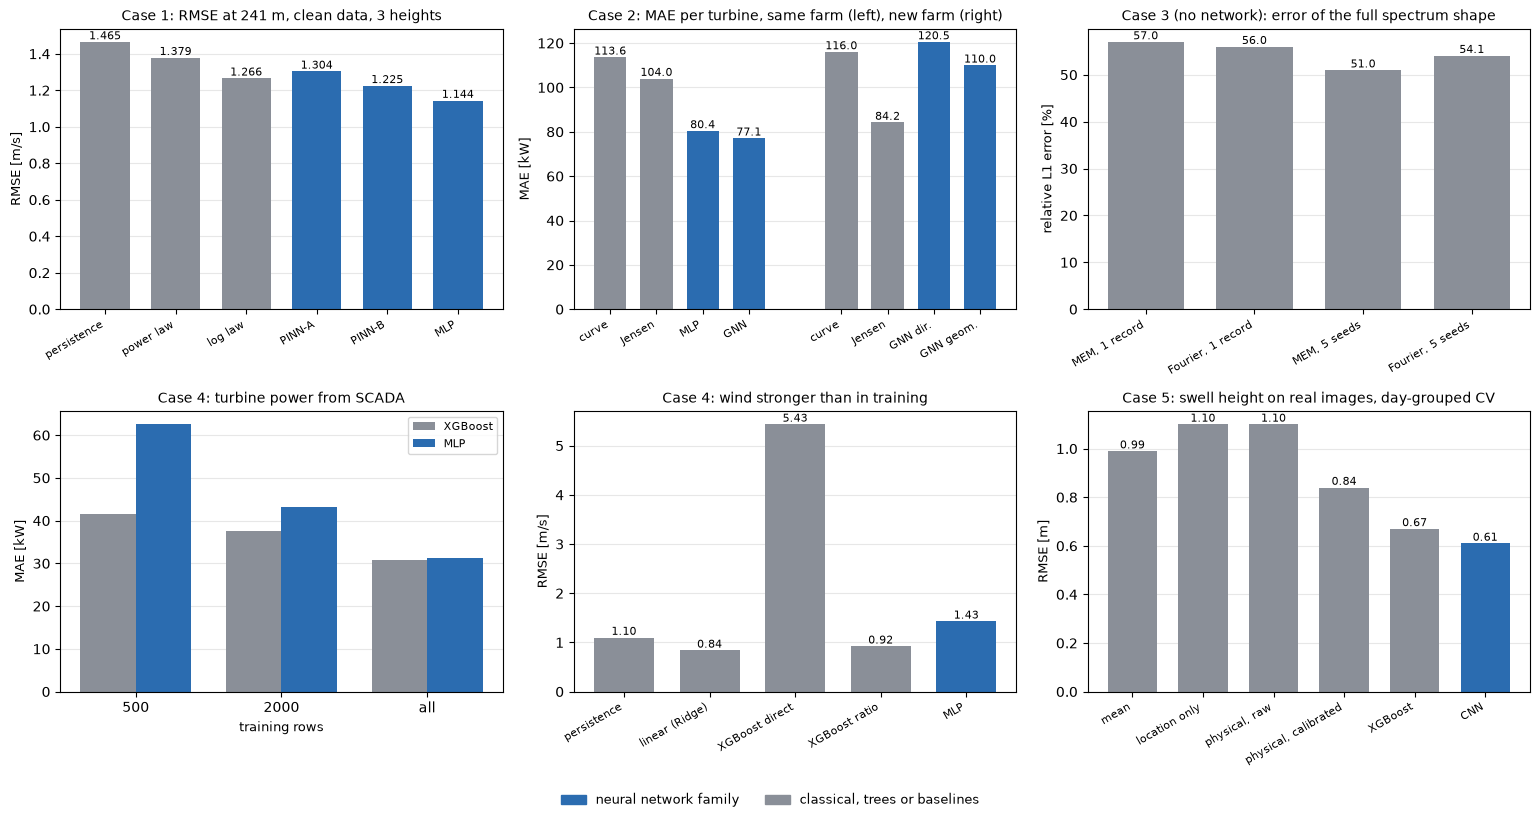

In [3]:
BLUE, GREY = "#2b6cb0", "#8a8f98"          # neural network family against classical / trees
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2))

def bars(ax, labels, keys, colors, title, ylabel, fmt="{:.2f}", rot=30):
    vals = [V(k) for k in keys]
    xs = np.arange(len(vals))
    ax.bar(xs, vals, color=colors, width=0.7)
    for x, v in zip(xs, vals):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(xs); ax.set_xticklabels(labels, rotation=rot, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[0, 0], ["persistence", "power law", "log law", "PINN-A", "PINN-B", "MLP"],
     ["pinn_epl241_persist", "pinn_epl241_pow", "pinn_epl241_log", "pinn_epl241_pinna", "pinn_epl241_pinnb", "pinn_epl241_mlp"],
     [GREY, GREY, GREY, BLUE, BLUE, BLUE],
     "Case 1: RMSE at 241 m, clean data, 3 heights", "RMSE [m/s]", "{:.3f}")

# case 2: two groups of bars in one panel
ax = axes[0, 1]
g1 = [("curve", "gnn_pen_curve", GREY), ("Jensen", "gnn_pen_jensen", GREY), ("MLP", "gnn_pen_mlp", BLUE), ("GNN", "gnn_pen_gnn", BLUE)]
g2 = [("curve", "gnn_kel_curve", GREY), ("Jensen", "gnn_kel_jensen", GREY), ("GNN dir.", "gnn_kel_gnn_dir", BLUE), ("GNN geom.", "gnn_kel_gnn_geom", BLUE)]
xs = list(range(len(g1))) + [len(g1) + 1 + i for i in range(len(g2))]
for x, (lab, k, c) in zip(xs, g1 + g2):
    ax.bar(x, V(k), color=c, width=0.7); ax.text(x, V(k), f"{V(k):.1f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([g[0] for g in g1 + g2], rotation=30, ha="right", fontsize=8)
ax.set_title("Case 2: MAE per turbine, same farm (left), new farm (right)", fontsize=10); ax.set_ylabel("MAE [kW]", fontsize=9)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[0, 2], ["MEM, 1 record", "Fourier, 1 record", "MEM, 5 seeds", "Fourier, 5 seeds"],
     ["wave_L1_mem", "wave_L1_four", "wave_L1_mem5", "wave_L1_four5"], [GREY] * 4,
     "Case 3 (no network): error of the full spectrum shape", "relative L1 error [%]", "{:.1f}")

# case 4: tabular data, both ends of the learning curve, and out of range
ax = axes[1, 0]
rowsx = [("500", "xgb_n500_xgb", "xgb_n500_mlp"), ("2000", "xgb_n2000_xgb", "xgb_n2000_mlp"), ("all", "xgb_nall_xgb", "xgb_nall_mlp")]
x = np.arange(len(rowsx)); w = 0.38
ax.bar(x - w / 2, [V(r[1]) for r in rowsx], w, color=GREY, label="XGBoost")
ax.bar(x + w / 2, [V(r[2]) for r in rowsx], w, color=BLUE, label="MLP")
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rowsx]); ax.set_xlabel("training rows", fontsize=9)
ax.set_title("Case 4: turbine power from SCADA", fontsize=10); ax.set_ylabel("MAE [kW]", fontsize=9)
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

bars(axes[1, 1], ["persistence", "linear (Ridge)", "XGBoost direct", "XGBoost ratio", "MLP"],
     ["xgb_oor_persist", "xgb_oor_ridge", "xgb_oor_xgb", "xgb_oor_ratio", "xgb_oor_mlp"],
     [GREY, GREY, GREY, GREY, BLUE], "Case 4: wind stronger than in training", "RMSE [m/s]", "{:.2f}")

bars(axes[1, 2], ["mean", "location only", "physical, raw", "physical, calibrated", "XGBoost", "CNN"],
     ["cnn_hs_mean", "cnn_hs_meta", "cnn_phys_rmse", "cnn_hs_cal", "cnn_hs_xgb", "cnn_hs_cnn"],
     [GREY, GREY, GREY, GREY, GREY, BLUE], "Case 5: swell height on real images, day-grouped CV", "RMSE [m]", "{:.2f}")

fig.legend(handles=[Patch(color=BLUE, label="neural network family"), Patch(color=GREY, label="classical, trees or baselines")],
           loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Reading.** In every panel the bars come straight from the notebooks. Lower is better. Case 1 shows that the plain MLP, not the physics-informed ones, led in the clean-data case; case 2 shows the reversal when the farm is new; case 3 is a reminder that two classical reconstructions can both be about half wrong in shape; case 4 shows the tree winning on a table and failing out of range, where a linear model and a tree with a good target do best; case 5 shows the network and the trees tied, both far ahead of the raw physics and of the mean. Colour is a family label (network or not), not a verdict. These are single studies on a few sites and seeds: read them as evidence about *mechanisms*, not as rankings that will repeat elsewhere.

## 9. Cross-cutting lessons

1. **Baselines first, and strong ones.** Persistence, a log law, a fitted Jensen model, the always-the-mean predictor and XGBoost were the opponents. In case 5 the mean was the baseline that the raw physical method failed to beat (1.10 m against 0.99 m). In case 2, a one-parameter model beat a network when the physics was simple. A network that is only compared with a weak baseline proves nothing.
2. **Honest validation matches the use.** Later months for forecasting, a different farm for transfer, a different altitude range for extrapolation, and **whole days held out** for images that see the same storm (86 days, not 187 images). A random split would have flattered every model in these notebooks. Seed variation, independent-sample counts and "this is a pilot" are stated where they apply.
3. **Physics is a prior, not an oracle.** It helped as a regulariser (case 1, noisy and scarce data), as a boundary condition (zero speed at the surface), and as a way to choose the target (the shear ratio in case 4). It cost 65 % where the equation did not hold (case 1, hill). The amount of physics is a design choice with a knob ($\lambda$) that needs validation.
4. **Labels, not architecture.** In case 5 the pilot with 8 images gave a CNN that learned nothing, and with 187 labelled images it cut the height error by 38 % against the mean. In case 2 the **edge features** and the **diversity of farms** mattered more than attention against sum aggregation. Compare module 13 of this course.
5. **Controls that can fail.** A location-only model that must not beat the mean; a random property that a probe must not predict; a synthetic bench with known truth in which the answer is known; a reference "with advantage" (a tall lidar) to show that the missing information is not in the data (case 1). A result that has never been exposed to a control is a result you cannot yet trust.
6. **Report the negatives and the cost.** Every notebook has a section that lists what failed, and the cost is reported (17 s against 156 s of training in case 4). A model that wins by 2 % and is nine times cheaper to maintain is a different decision from one that wins by 2 % and is nine times costlier.
7. **Know what the model cannot do.** None of these networks extrapolated; none recovered atmospheric stability from three noisy heights; none gave a direction from a single intensity image without extra information. Say it, and propose the measurement that would fix it.

## 10. Extending each case with the newer modules

These are **suggestions for extra work**, not results: none of them was run in the notebooks (the notebooks' own exercises list some).

| Case | Extension | Module |
|---|---|---|
| 1 PINN | A neural operator that learns the profile as a function of height *and* of stability over many profiles, instead of one network per profile. | [09, scientific machine learning](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| | Conformal or ensemble intervals around the extrapolated speed, because one number without an interval hides how uncertain the speed is at the top. | [11, uncertainty](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| | Measure which inputs the global network uses, as the linear probe did in case 5. | [10, interpretability](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| 2 GNN | The notebook's own "physics-guided" proposals: the Jensen deficit as an edge feature, a residual output around Jensen, a wake term in the loss; untested here. | [08, graph networks](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| | Pre-train on many farms and adapt a few weights per new farm (fine-tuning, adapters) instead of retraining. | [02, fine-tuning](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| | Intervals for the farm total, which is what an operator bids. | [11, uncertainty](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| 3 Wave spectra | An autoencoder to compress or denoise spectra; a learned estimator of the direction distribution that is trained on simulated truth. | [04, autoencoders](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| 4 XGBoost against PyTorch | Time-series models and hybrids (trees for short horizons, a network for long ones); quantile forecasts. | [07 of 1001](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) and [11](https://neural-networks-1002.academy.forwardforecasting.eu/) |
| 5 CNN on radar | Pre-train on a large archive of unlabelled radar images with self-supervision and fine-tune on the 187 labelled ones; an uncertainty method for the underestimated extremes; a second site and a buoy as an independent reference. | [04, self-supervised learning](https://neural-networks-1002.academy.forwardforecasting.eu/), [11, uncertainty](https://neural-networks-1002.academy.forwardforecasting.eu/), [13, data-centric AI](https://neural-networks-1002.academy.forwardforecasting.eu/) |

For agents that run such comparisons automatically, see the sibling course on [RAG systems](https://rag-systems.academy.forwardforecasting.eu/), in particular [agents with LangGraph](https://rag-systems.academy.forwardforecasting.eu/05-agents-with-langgraph/).

## 11. Limits and licences

**Limits of the evidence.**

* **Few sites, short records, small test sets.** One farm and one year for most of case 4; one South Pacific site and one year for case 5; 400 test profiles and a single noise realisation for the first part of case 1; two real farms for case 2. Differences of a few percent between methods are within seed and sampling noise and the notebooks say so.
* **Synthetic benches show mechanisms, not real percentages.** The simulators in cases 2 and 5 contain the physics we put in them. A good number on a simulator is consistency with the simulator.
* **ERA5 is not the ground truth.** It is a reanalysis, a wave model that assimilates measurements, and may share errors with what the network learns. No buoy exists near the site of case 5.
* **Day-grouped validation leaves 86 independent days.** The difference between the CNN and XGBoost is not conclusive.
* **Reading numbers across notebooks.** The notebooks use the Spanish decimal comma in text and decimal points in printed tables; in a few places the prose rounds a value slightly differently from the table. This module quotes the table when they differ.
* **No claim about operational performance.** Nothing here is a validated forecasting or load-estimation product.

**Data licences (read before reusing or publishing).**

| Data | Where used | Licence or terms |
|---|---|---|
| Offshore lidar extracts at the two platforms and the lighthouse (from a Dutch offshore wind-measurement portal) | case 1 | **No explicit licence declared.** Used here for teaching with attribution; check the portal terms before any commercial use or redistribution |
| Altahullion wind farm open data set, [doi:10.5281/zenodo.19948235](https://doi.org/10.5281/zenodo.19948235) | case 1 | CC BY 4.0 (attribution) |
| Penmanshiel and Kelmarsh SCADA, [doi:10.5281/zenodo.5946808](https://doi.org/10.5281/zenodo.5946808), [doi:10.5281/zenodo.5841834](https://doi.org/10.5281/zenodo.5841834) (Plumley, 2022) | cases 2 and 4 | CC BY 4.0 (attribution) |
| TenGeoP-SARwv radar image extract, [doi:10.17882/56796](https://doi.org/10.17882/56796) (Wang et al., 2019, derived from Copernicus Sentinel-1 data) | cases 3 and 5 | **CC BY-NC-SA 4.0: non-commercial use only, and derived material must be shared under the same licence** |
| Radar-derived spectra of 187 images of 2016 (`sar_sitio_2016_espectros.npz`, no images) and 8 images of January 2016 (`sar_sitio_2016.npz`) | case 5 | **Same licence, CC BY-NC-SA 4.0: non-commercial** |
| ERA5 values interpolated to the images, [doi:10.1002/qj.3803](https://doi.org/10.1002/qj.3803) (Hersbach et al., 2020; Copernicus Climate Change Service) | case 5 | Copernicus licence, with attribution |
| NOAA National Data Buoy Center, station 46042, [station page](https://www.ndbc.noaa.gov/station_page.php?station=46042) | case 3 | public data |

The text and code of the notebooks belong to the course; **the data keep the licence of their origin, and several are for non-commercial use only.** If you plan commercial work, you need to obtain the data again under terms that allow it.

## 12. Key takeaways, exercises, references

**Key takeaways**

* The question is never "network or not", but **under which conditions** the network wins. Five real problems gave a consistent answer: it wins on structured inputs (graphs, images) with enough diversity or real labels, with many related outputs, and as a physics-regularised model on scarce or noisy data; it ties or loses on small tabular data, against a well-specified simple model, and outside the range it was trained on.
* **Physics is a regulariser and a boundary condition**, valuable where it holds and costly where it does not (65 % worse on the hill).
* **Generalisation comes from diversity**: a network trained on one farm learned that farm (59.4 kW on new farms against 30.7 kW on its own).
* **Labels beat architecture** (CNN and XGBoost tied once labels from a reanalysis were used).
* **Validate as you will use**, include controls that can fail, and report the negatives and the cost.
* **Mind the licences**: several of the data are non-commercial.

**Exercises**

1. Open notebook 01 and change the weight $\lambda$ for the first offshore platform with noise, as its exercise 1 proposes. Where is the optimum and does it move with the noise?
2. In notebook 02, section 20, add a third fine-tuning window of two months. Where does the pre-trained network cross the fitted Jensen model?
3. In notebook 04, implement the hybrid suggested in its conclusion (XGBoost up to 1 hour, MLP afterwards). How much does the mean error drop, and what does it cost to maintain?
4. In notebook 05, use the 86 days of section 6.5 to compute a bootstrap confidence interval (resampling days) for the difference in height RMSE between the CNN and XGBoost. Does it include zero?
5. Pick one result of this module that you find surprising and write down (a) the baseline it was compared with, (b) the validation split, (c) the control that could have shown it to be an artefact, and (d) the cost. Which of the four is weakest?
6. Choose a problem of your own (any sector) and fill in the row of the table of section 1: problem, data, technologies, winner, lesson. Decide in advance what would make you say the network lost.

**References** (every link was opened and the title, authors and year checked against the landing page or DOI record)

* Raissi, M., Perdikaris, P. and Karniadakis, G. E. (2019). Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics* 378, 686-707: https://doi.org/10.1016/j.jcp.2018.10.045
* Foken, T. (2006). 50 years of the Monin-Obukhov similarity theory. *Boundary-Layer Meteorology* 119, 431-447: https://doi.org/10.1007/s10546-006-9048-6
* Jensen, N. O. (1983). A note on wind generator interaction. Risoe-M-2411, Risoe National Laboratory: https://orbit.dtu.dk/en/publications/a-note-on-wind-generator-interaction
* Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O. and Dahl, G. E. (2017). Neural message passing for quantum chemistry. ICML. arXiv:1704.01212: https://arxiv.org/abs/1704.01212
* Battaglia, P. W. et al. (2018). Relational inductive biases, deep learning, and graph networks. arXiv:1806.01261: https://arxiv.org/abs/1806.01261
* Plumley, C. (2022). Penmanshiel wind farm data: https://doi.org/10.5281/zenodo.5946808 . Kelmarsh wind farm data: https://doi.org/10.5281/zenodo.5841834 (both CC BY 4.0).
* Lygre, A. and Krogstad, H. E. (1986). Maximum entropy estimation of the directional distribution in ocean wave spectra. *Journal of Physical Oceanography* 16(12), 2052-2060: https://doi.org/10.1175/1520-0485(1986)016%3C2052:MEEOTD%3E2.0.CO;2
* Alpers, W. R., Ross, D. B. and Rufenach, C. L. (1981). On the detectability of ocean surface waves by real and synthetic aperture radar. *Journal of Geophysical Research* 86(C7), 6481-6498: https://doi.org/10.1029/JC086iC07p06481
* Hasselmann, K. and Hasselmann, S. (1991). On the nonlinear mapping of an ocean wave spectrum into a synthetic aperture radar image spectrum and its inversion. *Journal of Geophysical Research* 96(C6), 10713-10729: https://doi.org/10.1029/91JC00302
* Wang, C., Mouche, A., Tandeo, P. et al. (2019). A labelled ocean SAR imagery dataset of ten geophysical phenomena from Sentinel-1 wave mode. *Geoscience Data Journal* 6(2), 105-115: https://doi.org/10.1002/gdj3.73 . Data: https://doi.org/10.17882/56796 (CC BY-NC-SA 4.0).
* Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society* 146(730), 1999-2049: https://doi.org/10.1002/qj.3803 . Data: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels
* Chen, T. and Guestrin, C. (2016). XGBoost: a scalable tree boosting system. KDD, 785-794: https://doi.org/10.1145/2939672.2939785 , arXiv:1603.02754: https://arxiv.org/abs/1603.02754
* Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? NeurIPS Datasets and Benchmarks. arXiv:2207.08815: https://arxiv.org/abs/2207.08815
* NOAA National Data Buoy Center, station 46042: https://www.ndbc.noaa.gov/station_page.php?station=46042

In [4]:
print(f"{len(QUOTED)} quoted numbers, all verified against the five notebooks of wind_cases/")

188 quoted numbers, all verified against the five notebooks of wind_cases/
